# Monitoreo de demanda de MiBici
**Equipo 9 · Entrega final, punto 5 · Octubre de 2026 · Modelo v3**

El equipo ya comparó el modelo congelado, un reentrenamiento al corte y el naïve estacional entre junio y septiembre. El **20 de noviembre de 2026** verificamos que MiBici ya ofrecía un CSV para **octubre**, posterior al cierre de la versión silver 001. Extendimos el pipeline y repetimos la evaluación con esa ventana. La fecha corresponde a la verificación de disponibilidad del archivo.

El notebook responde dos preguntas: ¿cambiaron las entradas del modelo en octubre? ¿Qué pasa con el error si alteramos de forma controlada la señal de salidas? La comparación real y el estrés sintético usan el artefacto congelado v3 que sirve la API. [Portal de datos abiertos de MiBici](https://mibici.net/es/datos-abiertos/) · [CSV de octubre](https://mibici.net/site/assets/files/133188/datos_abiertos_2026_10.csv)

## 1. Configuración y ventanas

La referencia es abril–mayo de 2026. La ventana real se define por la **hora objetivo** y conserva el historial necesario para calcular rezagos. Octubre ya se exploró para detectar el aumento de viajes. Aquí se evalúa el desempeño del modelo v3 sobre ese mes.

Ejecuta desde la raíz del repositorio o desde `notebooks/`. El notebook usa por defecto la exportación del servicio en `models/`. Si está en otro checkout, indica su directorio con `MIBICI_MODELOS_DIR`. Hay dos opciones para cargar el modelo: la exportación local de la API o la URI fija de la v3 del registro. Las métricas se escriben en una carpeta separada por versión. Con `MIBICI_REGISTRAR_MLFLOW=1`, la evaluación se registra en el servidor indicado y se verifica que ese servidor contenga la v3 del equipo.

In [1]:
import json
import os
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

MES = os.environ.get("MIBICI_MES", "2026-10")
VERSION_MODELO = "3"
URI_V3 = f"models:/mibici-demanda-zona-hora/{VERSION_MODELO}"
REGISTRAR = os.environ.get("MIBICI_REGISTRAR_MLFLOW") == "1"
TRACKING_URI = os.environ.get("MIBICI_TRACKING_URI")
MODELO_URI = os.environ.get("MIBICI_MODELO_URI")
CSV_PREVIOS = {}  # Para meses posteriores, usa {"AAAA-MM": Path("ruta_al_csv")}.

inicio = Path(os.environ.get("MIBICI_PROYECTO", Path.cwd())).resolve()
raiz = next(
    (p for p in (inicio, *inicio.parents)
     if (p / "reports/modelado/resultado_prueba.json").is_file()),
    None,
)
if raiz is None:
    raise FileNotFoundError("Define MIBICI_PROYECTO con la raíz del checkout de modelado.")

modelos_dir = Path(os.environ.get("MIBICI_MODELOS_DIR", raiz / "models"))
if "MIBICI_MODELOS_DIR" not in os.environ and not (modelos_dir / "modelo_servicio.json").is_file():
    # En este equipo la exportación está en el clon que contiene el PR de Docker.
    clon_pr = raiz.parents[1] / "PR Drift" / raiz.name / "models"
    if (clon_pr / "modelo_servicio.json").is_file():
        modelos_dir = clon_pr

work = Path(os.environ.get("MIBICI_MONITOREO_WORK", raiz / "data/processed/monitoreo"))
reportes = Path(os.environ.get("MIBICI_REPORTES_DRIFT", raiz / "reports/drift"))
salida_publicada = reportes / f"v{VERSION_MODELO}" / "monthly" / MES
salida = salida_publicada if REGISTRAR else work / "previsualizacion" / f"v{VERSION_MODELO}" / MES

## 2. El nuevo mes en datos reales

Se aplica la política de limpieza de silver 001 y se mantiene fijo su catálogo de estaciones para conservar la geografía de referencia. La evidencia guarda la huella del CSV, los descartes y las estaciones fuera del catálogo. La comparación mensual de volumen usa registros crudos y ajusta por días del mes. La siguiente sección mide el cambio en las variables generadas por el pipeline.

In [2]:
from proyecto_mlops_equipo_9.monitoring_data import download_october, prepare_month

dataset_preparado = os.environ.get("MIBICI_FEATURES")
csv_mes = os.environ.get("MIBICI_CSV_MES")
if dataset_preparado:
    features = Path(dataset_preparado)
else:
    if not csv_mes and MES != "2026-10":
        raise ValueError("Define MIBICI_CSV_MES con el CSV oficial del mes.")
    csv = Path(csv_mes) if csv_mes else download_october(work / "datos_abiertos_2026_10.csv")
    features = prepare_month(raiz, MES, csv, work, prior_csvs=CSV_PREVIOS)

fuente = json.loads(features.with_suffix(".sources.json").read_text(encoding="utf-8"))
if MES == "2026-10":
    fuente["disponibilidad_verificada_el"] = "2026-11-20"
origen = next(f for f in fuente["fuentes_mensuales"] if f["periodo"] == MES)
display(pd.DataFrame([origen])[[
    "periodo", "filas_crudas", "filas_aceptadas", "filas_excluidas",
    "estaciones_origen_crudas", "estaciones_origen_aceptadas",
]])
print(f"SHA-256 del CSV: {origen['sha256']}")

historico = pd.read_csv(raiz / "data/silver/version_001/metadatos/resumen_mensual.csv")
historico["mes"] = historico.mes.str.replace("_", "-")
registros = historico.set_index("mes")["originales"]
mes_actual = pd.Period(MES, freq="M")
meses = [str(mes_actual - 12), str(mes_actual - 1), MES]
registros = pd.concat([
    registros, pd.Series({f["periodo"]: f["filas_crudas"] for f in fuente["fuentes_mensuales"]})
])
volumen = registros.reindex(meses).dropna().rename("registros_crudos").to_frame()
volumen["registros_por_dia"] = [
    round(int(n) / pd.Period(m, freq="M").days_in_month, 1)
    for m, n in volumen.registros_crudos.items()
]
display(volumen)
for anterior in volumen.index[:-1]:
    variacion = volumen.loc[MES, "registros_por_dia"] / volumen.loc[anterior, "registros_por_dia"] - 1
    print(f"Cambio de {MES} frente a {anterior}: {variacion:+.1%} registros por día")


,periodo,filas_crudas,filas_aceptadas,filas_excluidas,estaciones_origen_crudas,estaciones_origen_aceptadas
0,2026-10,635532,608074,27458,470,469


SHA-256 del CSV: 0cdfb05299e6db658ac9cc7723494a9704b0749e3671c29c8566826ea889b900


,registros_crudos,registros_por_dia
2025-10,420064,13550.5
2026-09,490056,16335.2
2026-10,635532,20501.0


Cambio de 2026-10 frente a 2025-10: +51.3% registros por día
Cambio de 2026-10 frente a 2026-09: +25.5% registros por día


## 3. Referencia, simulación y modelo congelado

- **Modelo evaluado.** HistGradientBoosting v3, alias `campeon` al exportarlo. Usamos la copia que carga la API y comprobamos la huella del directorio y las predicciones de la exportación. La evaluación mensual usa las mismas funciones de predicción del equipo.
- **Naïve estacional.** Usa los conteos de la misma zona y hora de la semana anterior. Ambos modelos se evalúan sobre filas pareadas.
- **Simulación.** Aplicamos un sobreconteo de +20% y +40% a la telemetría de salidas, sus rezagos y medias móviles. Las claves, etiquetas y cobertura se conservan. Los factores son escenarios de estrés, independientes del mecanismo que produjo el cambio de octubre.
- **Reglas piloto.** Revisamos las entradas si cambia al menos 25% una señal comparable y el desempeño si sube al menos 20% el MAE. Una ventaja frente al naïve inferior a 10% activa una tercera revisión. Las entradas se comparan con igual peso por zona, hora y día de la semana en estratos comunes. La alerta de MAE se calcula en las zonas comunes.

In [3]:
from hashlib import sha256
from importlib.metadata import version
import platform

import mlflow.sklearn

from proyecto_mlops_equipo_9.modeling.predict import predecir
from proyecto_mlops_equipo_9.monitoring import (
    ejecutar_monitoreo, registrar_evaluacion, verificar_tracking,
)

registro = None
if MODELO_URI:
    if MODELO_URI != URI_V3 or not TRACKING_URI:
        raise ValueError(f"Usa {URI_V3} y configura MIBICI_TRACKING_URI.")
    cliente = verificar_tracking(TRACKING_URI)
    registro = cliente.get_model_version("mibici-demanda-zona-hora", VERSION_MODELO)
    modelo = mlflow.sklearn.load_model(MODELO_URI)
    identidad = {"id": MODELO_URI, "origen": "registro_mlflow", "run_modelo": registro.run_id}
else:
    ruta_metadata = modelos_dir / "modelo_servicio.json"
    if not ruta_metadata.is_file():
        raise FileNotFoundError("Indica MIBICI_MODELOS_DIR con el directorio models de la API.")
    servicio = json.loads(ruta_metadata.read_text(encoding="utf-8"))
    if servicio["uri_registro"] != URI_V3 or str(servicio["version"]) != VERSION_MODELO:
        raise ValueError(f"La exportación de la API debe corresponder a {URI_V3}.")
    carpeta_modelo = modelos_dir / servicio["directorio"]
    # Se ordenan rutas POSIX como texto para replicar el SHA de la exportación en Linux.
    archivos = sorted(p.relative_to(carpeta_modelo).as_posix()
                      for p in carpeta_modelo.rglob("*") if p.is_file())
    huella = sha256()
    for nombre in archivos:
        huella.update(nombre.encode("utf-8"))
        huella.update(sha256((carpeta_modelo / nombre).read_bytes()).digest())
    if huella.hexdigest() != servicio["sha256_modelo"]:
        raise ValueError("El directorio del modelo difiere de la exportación documentada.")
    modelo = mlflow.sklearn.load_model(str(carpeta_modelo))

    datos_servicio = pd.read_parquet(modelos_dir / servicio["datos"]["archivo"])
    predicciones_ref = pd.read_parquet(modelos_dir / servicio["datos"]["referencia"])
    llaves = ["zona_id", "inicio_hora_objetivo"]
    comparacion_servicio = predicciones_ref.merge(
        predecir(modelo, datos_servicio), on=llaves, suffixes=("_ref", "_v3"),
        validate="one_to_one", how="outer", indicator=True,
    )
    if not comparacion_servicio["_merge"].eq("both").all():
        raise ValueError("Las claves del pronóstico difieren de la referencia de la API.")
    desviacion = max(
        (comparacion_servicio[f"{c}_ref"] - comparacion_servicio[f"{c}_v3"]).abs().max()
        for c in servicio["salidas"]
    )
    if desviacion > 1e-6:
        raise ValueError("El modelo cargado difiere de las predicciones de referencia de la API.")
    identidad = {
        "id": URI_V3, "origen": "exportacion_verificada_de_la_api",
        "version": VERSION_MODELO, "run_modelo": servicio["run_id"],
        "sha256_exportacion": huella.hexdigest(),
        "verificacion_api": {"filas": len(comparacion_servicio), "desviacion_maxima": float(desviacion)},
        "entorno_exportacion": servicio["entorno"],
    }
    print(f"Exportación v3 verificada en {len(comparacion_servicio):,} predicciones de referencia.")
    print(f"Diferencia máxima con la referencia de la API: {desviacion:.2g}")

identidad["entorno_evaluacion"] = {"python": platform.python_version()} | {
    p: version(p) for p in ("mlflow", "scikit-learn", "skops", "numpy", "pandas", "pyarrow")
}
resultados = ejecutar_monitoreo(features, MES, modelo, identidad, salida, fuente=fuente)
metricas, drift, alertas, evidencia = resultados
print(identidad["id"])
print(f"{evidencia['mes_real']['filas']:,} filas zona-hora en {evidencia['mes_real']['zonas']} zonas")
print(f"{evidencia['mes_real']['horas_objetivo_evaluables']} de "
      f"{evidencia['mes_real']['horas_calendario']} horas calendario con filas evaluables")

Exportación v3 verificada en 11,840 predicciones de referencia.
Diferencia máxima con la referencia de la API: 1.4e-14


models:/mibici-demanda-zona-hora/3
52,400 filas zona-hora en 80 zonas
655 de 744 horas calendario con filas evaluables


## 4. Resultados y decisión

El MAE mide viajes de error por zona y hora. WAPE divide el error absoluto por el volumen observado. En un mes con más demanda, el MAE y WAPE pueden moverse en direcciones distintas. La ventaja frente al naïve ayuda a determinar si el modelo sigue aportando valor para la operación.

filas_pareadas     mae  mae_salidas  \
escenario             modelo                                                  
referencia_abril_mayo modelo_fijo                85338  2.0032       2.0163   
                      naive_estacional           85338  2.8372       2.8667   
mes_real              modelo_fijo                43230  3.1329       3.0993   
                      naive_estacional           43230  3.9529       3.9582   
sintetico_20          modelo_fijo                85338  2.1756       2.3244   
                      naive_estacional           85338  3.1539       3.5000   
sintetico_40          modelo_fijo                85338  2.4750       2.8843   
                      naive_estacional           85338  3.6686       4.5294   

                                        mae_llegadas  mae_flujo_neto    wape  
escenario             modelo                                                  
referencia_abril_mayo modelo_fijo             1.9902          2.1973  0.2643  
                      naive_estacional        2.8078          2.8217  0.3743  
mes_real              modelo_fijo             3.1664          2.9613  0.2295  
                      naive_estacional        3.9475          3.4236  0.2896  
sintetico_20          modelo_fijo             2.0267          2.3507  0.2870  
                      naive_estacional        2.8078          3.3462  0.4161  
sintetico_40          modelo_fijo             2.0657          2.7309  0.3265  
                      naive_estacional        2.8078          4.3485  0.4840

zonas_comunes  estratos_comunes  \
escenario    variable                                            
mes_real     salidas                      66              9900   
             llegadas                     66              9900   
             salidas_lag_23h              66              9900   
             llegadas_lag_23h             66              9900   
sintetico_20 salidas                      66             10164   
             llegadas                     66             10164   
             salidas_lag_23h              66             10164   
             llegadas_lag_23h             66             10164   
sintetico_40 salidas                      66             10164   
             llegadas                     66             10164   
             salidas_lag_23h              66             10164   
             llegadas_lag_23h             66             10164   

                               media_referencia  media_actual  cambio_relativo  
escenario    variable                                                           
mes_real     salidas                     7.5331       13.4607           0.7869  
             llegadas                    7.5278       13.4615           0.7882  
             salidas_lag_23h             7.5317       13.4149           0.7811  
             llegadas_lag_23h            7.5317       13.4210           0.7819  
sintetico_20 salidas                     7.3376        8.8051           0.2000  
             llegadas                    7.3369        7.3369           0.0000  
             salidas_lag_23h             7.3361        8.8033           0.2000  
             llegadas_lag_23h            7.3363        7.3363           0.0000  
sintetico_40 salidas                     7.3376       10.2726           0.4000  
             llegadas                    7.3369        7.3369           0.0000  
             salidas_lag_23h             7.3361       10.2706           0.4000  
             llegadas_lag_23h            7.3363        7.3363           0.0000

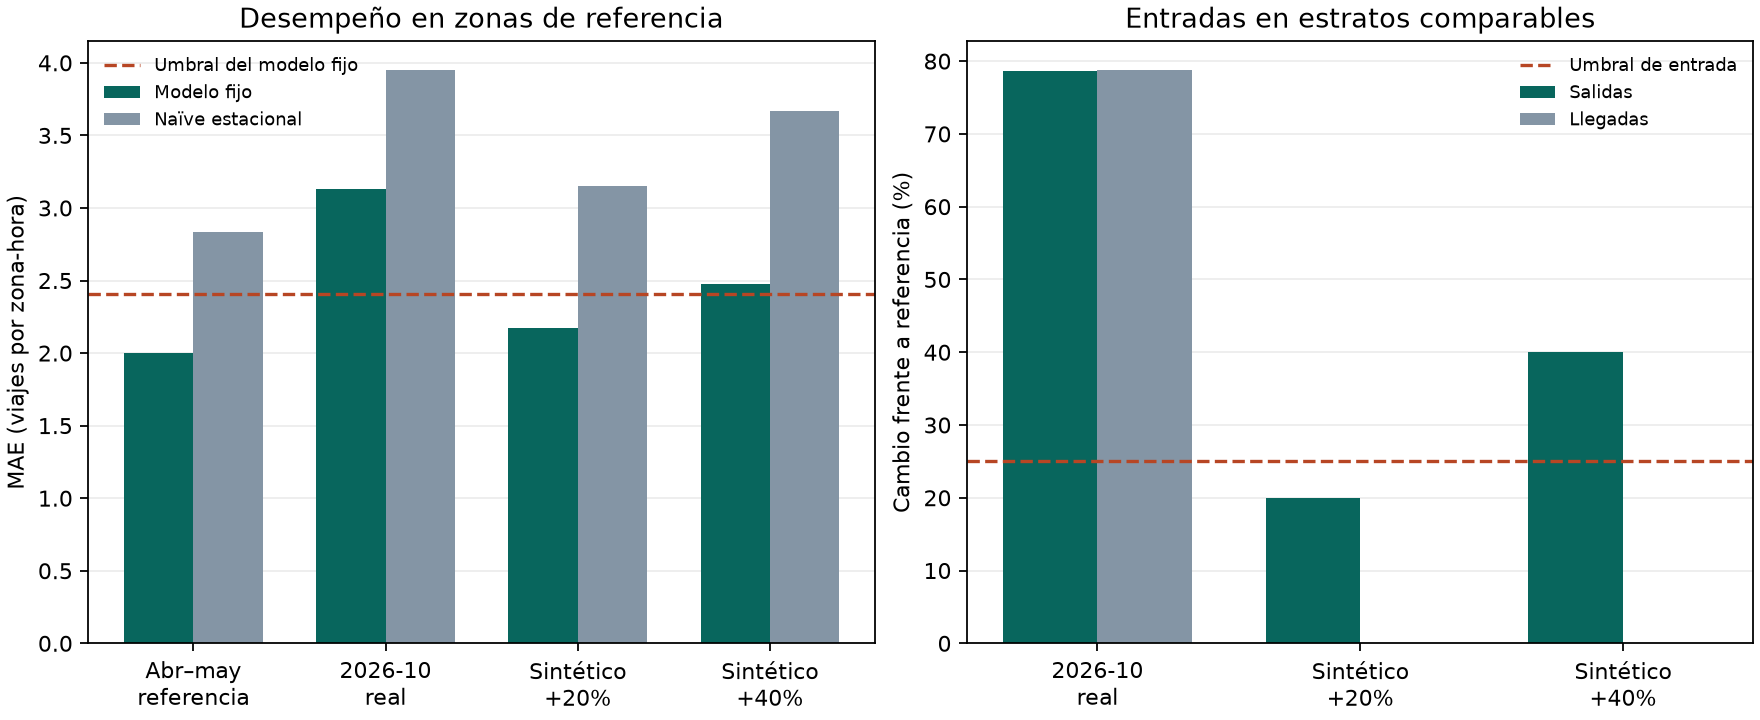

In [4]:
columnas = ["filas_pareadas", "mae", "mae_salidas", "mae_llegadas", "mae_flujo_neto", "wape"]
comunes = metricas.loc[metricas.segmento.eq("zonas_referencia")]
display(comunes.set_index(["escenario", "modelo"])[columnas].round(4))
display(drift.set_index(["escenario", "variable"])[[
    "zonas_comunes", "estratos_comunes", "media_referencia", "media_actual", "cambio_relativo"
]].round(4))
display(Image(filename=str(salida / "monitoreo.png")))


In [5]:
comparacion = comunes.pivot(index="escenario", columns="modelo", values=["mae", "wape"])
referencia = comparacion.loc["referencia_abril_mayo"]
real = comparacion.loc["mes_real"]
cambio_mae = real["mae", "modelo_fijo"] / referencia["mae", "modelo_fijo"] - 1
ventaja = 1 - real["mae", "modelo_fijo"] / real["mae", "naive_estacional"]
salidas = drift.loc[drift.escenario.eq("mes_real") & drift.variable.eq("salidas"), "cambio_relativo"].item()
d20 = comparacion.loc["sintetico_20", ("mae", "modelo_fijo")] / referencia["mae", "modelo_fijo"] - 1
d40 = comparacion.loc["sintetico_40", ("mae", "modelo_fijo")] / referencia["mae", "modelo_fijo"] - 1
display(Markdown(
    f"**{MES}, datos reales.** En {evidencia['mes_real']['zonas_comunes']} zonas comunes, "
    f"la media comparable de salidas cambió **{salidas:+.1%}** y el MAE **{cambio_mae:+.1%}**. "
    f"El modelo conservó una ventaja de **{ventaja:.1%}** frente al naïve. "
    f"El WAPE pasó de {referencia['wape', 'modelo_fijo']:.1%} a {real['wape', 'modelo_fijo']:.1%}.\n\n"
    f"**Estrés sintético.** El MAE cambió {d20:+.1%} con el sobreconteo de 20% y "
    f"{d40:+.1%} con el de 40%."
))
activadas = alertas.loc[alertas.activada, ["escenario", "regla", "valor", "umbral", "accion_propuesta"]]
display(activadas.reset_index(drop=True))


**2026-10, datos reales.** En 66 zonas comunes, la media comparable de salidas cambió **+78.7%** y el MAE **+56.4%**. El modelo conservó una ventaja de **20.7%** frente al naïve. El WAPE pasó de 26.4% a 23.0%.

**Estrés sintético.** El MAE cambió +8.6% con el sobreconteo de 20% y +23.5% con el de 40%.

,escenario,regla,valor,umbral,accion_propuesta
0,mes_real,entrada_salidas,0.786887,0.25,"Revisar fuente, cobertura y conteos antes de a..."
1,mes_real,entrada_llegadas,0.788244,0.25,"Revisar fuente, cobertura y conteos antes de a..."
2,mes_real,entrada_salidas_lag_23h,0.781118,0.25,"Revisar fuente, cobertura y conteos antes de a..."
3,mes_real,entrada_llegadas_lag_23h,0.781933,0.25,"Revisar fuente, cobertura y conteos antes de a..."
4,mes_real,aumento_mae,0.563911,0.20,Revisar error por zona y hora. Si persiste con...
5,sintetico_40,entrada_salidas,0.400000,0.25,"Revisar fuente, cobertura y conteos antes de a..."
6,sintetico_40,entrada_salidas_lag_23h,0.400000,0.25,"Revisar fuente, cobertura y conteos antes de a..."
7,sintetico_40,aumento_mae,0.235496,0.20,Revisar error por zona y hora. Si persiste con...


In [6]:
# Contexto histórico, usando solo reportes de la v3.
reporte_modelado = modelos_dir.parent / "reports/modelado"
ficha_prueba = reporte_modelado / "resultado_prueba.json"
if ficha_prueba.is_file():
    prueba = json.loads(ficha_prueba.read_text(encoding="utf-8"))
    if str(prueba["version_registro"]) == VERSION_MODELO:
        historico_mae = pd.read_csv(reporte_modelado / "drift_mensual.csv").set_index("mes")
        historico_mae = historico_mae[["mae_fijo", "mae_linea_base"]].rename(
            columns={"mae_fijo": "modelo_fijo", "mae_linea_base": "naive_estacional"}
        )
        mes_mae = metricas.loc[
            metricas.escenario.eq("mes_real") & metricas.segmento.eq("total")
        ].set_index("modelo")["mae"]
        historico_mae.loc[MES] = mes_mae
        display(historico_mae.round(4))
        maes = metricas.loc[
            metricas.escenario.eq("referencia_abril_mayo") & metricas.segmento.eq("total")
            & metricas.modelo.eq("modelo_fijo"), "mae"
        ]
        print(f"MAE de abril–mayo registrado al entrenar la v3: {prueba['prueba']['mae']:.6f}")
        print(f"MAE recalculado con el artefacto de la API: {maes.item():.6f}")
        print("Las alertas usan la referencia recalculada con el mismo artefacto y entorno.")

,modelo_fijo,naive_estacional
mes,,
2026-06,2.1386,2.9159
2026-07,1.9987,2.6548
2026-08,1.9059,2.4389
2026-09,2.4437,3.3006
2026-10,2.7844,3.4885


MAE de abril–mayo registrado al entrenar la v3: 2.003003
MAE recalculado con el artefacto de la API: 2.003237
Las alertas usan la referencia recalculada con el mismo artefacto y entorno.


La decisión de esta revisión es **investigar calidad, cobertura y error por zona antes de cambiar el modelo**. El aumento de MAE merece seguimiento. La ventaja frente al naïve y WAPE aportan contexto sobre el valor que la v3 conserva. Los datos públicos carecen de una variable de tipo de bicicleta para atribuir el cambio a un mecanismo concreto.

## 5. Registro y próxima revisión

Para registrar una evaluación se indica el servidor que contiene la base existente del equipo y la versión v3. El directorio de reportes de v3 tiene su propia evidencia mensual. La guía en `reports/drift/README.md` describe la preparación del siguiente mes completo.

In [7]:
if REGISTRAR:
    if not TRACKING_URI:
        raise ValueError("Indica MIBICI_TRACKING_URI con el backend existente.")
    cliente = verificar_tracking(TRACKING_URI)
    cliente.get_model_version("mibici-demanda-zona-hora", VERSION_MODELO)
    run = registrar_evaluacion(
        TRACKING_URI, salida, resultados,
        artifact_location=os.environ.get("MIBICI_MLFLOW_ARTIFACT_LOCATION"),
    )
    print(f"Corrida v3 registrada: {run}")
else:
    print("Evaluación v3 ejecutada en modo local. Los resultados se muestran en el notebook.")

Corrida v3 registrada: c9e8b3b2dac44000924dec3baff14490
